# Validação externa, categoria administrativa e outros algoritmos — CPC 2023

Este notebook complementa os notebooks 06 e 07 com três melhorias sugeridas pela aula de Agrupamento (IND2622) e pelo artigo de Marcatti, Zanella e Konrath (2024):

1. **Validação externa:** comparar os grupos com variáveis que não entraram no agrupamento, como fez o artigo.
2. **Categoria administrativa:** verificar se a diferença em Regime de Trabalho dos cursos da PUC-Rio decorre de compará-los com cursos públicos.
3. **Outras famílias de algoritmos:** hierárquico (Ward), mistura gaussiana (GMM), k-medoids e DBSCAN, ao lado do k-means.

O modelo de referência é o mesmo do notebook 06: oito indicadores padronizados (C2), K-means com K=4, semente 42. Os resultados são gravados em `resultados_notebook_08/`.

## Principais resultados

| Pergunta | Resposta |
|---|---|
| Os grupos se relacionam com variáveis externas? | Sim. A associação é forte com a faixa do CPC (V de Cramér 0,49) e com a categoria administrativa (0,45), e fraca com a área (0,12). |
| A diferença em Regime de Trabalho vem de comparar com públicas? | Em parte. Ela cai de −1,98 para −1,73 contra pares privados e para −1,43 contra todas as privadas da área, mas continua negativa nos 8 cursos. |
| Outro algoritmo dá grupos melhores? | Não. O k-means tem a maior silhueta (0,239), o menor Davies–Bouldin (1,37) e a maior estabilidade (0,97). |
| Separar públicas e privadas melhora a silhueta? | Não de forma relevante: o máximo é 0,248 (só privadas, K=2), contra 0,239 na base completa. |

## 1. Dados e modelo de referência

In [1]:
# Célula 1 — Importações e parâmetros

import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

from scipy.stats import chi2_contingency
from sklearn.cluster import AgglomerativeClustering, DBSCAN, KMeans
from sklearn.metrics import (
    adjusted_rand_score,
    davies_bouldin_score,
    pairwise_distances,
    silhouette_score
)
from sklearn.mixture import GaussianMixture
from sklearn.preprocessing import StandardScaler

# Mesmos parâmetros do notebook 06 (C2, K=4)
K = 4
SEMENTE = 42
N_INIT = 20
CODIGO_IES_PUC = 528

# Reamostragens para a estabilidade dos algoritmos
SEMENTES = list(range(42, 72))
FRACAO_AMOSTRA = 0.80

INDICADORES = [
    "Enade_2023", "IDD_2023", "Mestres_2023", "Doutores_2023",
    "Regime_Trabalho_2023", "Organizacao_Didatica_2023",
    "Infraestrutura_2023", "Oportunidades_2023"
]

NOMES_INDICADORES = [
    "ENADE", "IDD", "Mestres", "Doutores", "Regime de trabalho",
    "Organização didática", "Infraestrutura", "Oportunidades"
]

pasta_saida = Path("resultados_notebook_08")
pasta_figuras = pasta_saida / "figuras"
pasta_figuras.mkdir(parents=True, exist_ok=True)

COR_1 = "#2a78d6"
COR_2 = "#eb6834"
COR_3 = "#1baf7a"
COR_TEXTO = "#52514e"
COR_GRADE = "#e4e3df"

plt.rcParams.update({
    "figure.dpi": 110,
    "font.size": 10,
    "axes.edgecolor": COR_GRADE,
    "axes.labelcolor": COR_TEXTO,
    "axes.titlesize": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "axes.axisbelow": True,
    "grid.color": COR_GRADE,
    "grid.linewidth": 0.7,
    "xtick.color": COR_TEXTO,
    "ytick.color": COR_TEXTO,
    "legend.frameon": False
})


def salvar_figura(fig, nome):
    fig.savefig(pasta_figuras / nome, dpi=300, bbox_inches="tight")

In [2]:
# Célula 2 — Base analítica com a categoria administrativa do INEP

base = pd.read_csv(
    "dados/processados/base_analitica_1907_cursos.csv",
    encoding="utf-8-sig"
)
base.columns = base.columns.str.replace("﻿", "", regex=False).str.strip()

colunas_inep = [
    "Código do Curso",
    "Categoria Administrativa",
    "Organização Acadêmica",
    "CPC (Faixa)",
    "Nota Bruta – Regime de Trabalho",
    "Nota Padronizada - Regime de Trabalho"
]

inep = (
    pd.read_csv(
        "resultados/cpc_censo_2023.csv",
        sep=";",
        encoding="utf-8-sig",
        usecols=colunas_inep,
        low_memory=False
    )
    .drop_duplicates("Código do Curso")
)

base = base.merge(inep, on="Código do Curso", how="left", validate="one_to_one")

base["Tipo"] = np.where(
    base["Categoria Administrativa"].str.startswith("Pública"),
    "Pública",
    "Privada"
)

mascara_puc = base["Código da IES"].eq(CODIGO_IES_PUC)

print("Cursos:", len(base))
print("Sem categoria administrativa:", base["Categoria Administrativa"].isna().sum())
print("Cursos da PUC-Rio:", mascara_puc.sum())

print("\nCategoria administrativa")
display(base["Categoria Administrativa"].value_counts().to_frame("Cursos"))

Cursos: 1907
Sem categoria administrativa: 0
Cursos da PUC-Rio: 8

Categoria administrativa


,Cursos
Categoria Administrativa,
Privada com fins lucrativos,653
Pública Federal,514
Privada sem fins lucrativos,305
Comunitária/Confessional,283
Pública Estadual,131
Pública Municipal,13
Especial,8


In [3]:
# Célula 3 — O Regime de Trabalho igual a zero é um valor real?

colunas = [
    "Código do Curso",
    "Area_2023",
    "Nota Bruta – Regime de Trabalho",
    "Nota Padronizada - Regime de Trabalho",
    "Regime_Trabalho_2023"
]

print("Cursos da PUC-Rio (nota bruta = proporção de docentes em tempo integral ou parcial)")
display(base.loc[mascara_puc, colunas].sort_values("Código do Curso"))

zeros = base["Regime_Trabalho_2023"].eq(0)

print("Cursos com nota padronizada igual a zero:", zeros.sum())
print("Nota bruta desses cursos:")
display(base.loc[zeros, "Nota Bruta – Regime de Trabalho"].describe().round(3).to_frame())

Cursos da PUC-Rio (nota bruta = proporção de docentes em tempo integral ou parcial)


,Código do Curso,Area_2023,Nota Bruta – Regime de Trabalho,Nota Padronizada - Regime de Trabalho,Regime_Trabalho_2023
1139,23702,5902,0.643678,2.328,2.328
435,29445,5710,0.619565,2.464,2.464
801,29446,5806,0.753247,2.885,2.885
985,32655,5814,0.718310,2.840,2.840
1388,32975,6008,0.690476,2.969,2.969
1550,44431,6208,0.518182,1.903,1.903
133,59962,21,0.294118,0.000,0.000
1784,70523,6307,0.703125,3.070,3.070


Cursos com nota padronizada igual a zero: 31
Nota bruta desses cursos:


,Nota Bruta – Regime de Trabalho
count,31.000
mean,0.190
std,0.241
min,0.000
25%,0.000
50%,0.150
75%,0.272
max,0.929


In [4]:
# Célula 4 — Modelo de referência: C2, K=4 (o mesmo do notebook 06)

escalonador = StandardScaler()
X = escalonador.fit_transform(base[INDICADORES])

kmeans = KMeans(n_clusters=K, random_state=SEMENTE, n_init=N_INIT).fit(X)
base["Grupo"] = kmeans.labels_

tamanhos = base["Grupo"].value_counts().sort_index()

print("Tamanhos dos grupos:", tamanhos.to_dict())
print("Silhueta:", round(silhouette_score(X, base["Grupo"]), 4))

perfis = pd.DataFrame(
    kmeans.cluster_centers_,
    columns=NOMES_INDICADORES
).round(2)
perfis.index.name = "Grupo"
perfis["Cursos"] = tamanhos

print("\nCentróides em desvios-padrão (positivo = acima da média)")
display(perfis)

Tamanhos dos grupos: {0: 574, 1: 437, 2: 611, 3: 285}
Silhueta: 0.2388

Centróides em desvios-padrão (positivo = acima da média)


,ENADE,IDD,Mestres,Doutores,Regime de trabalho,Organização didática,Infraestrutura,Oportunidades,Cursos
Grupo,,,,,,,,,
0,-0.11,0.07,0.26,-0.19,-0.08,1.09,1.10,1.00,574
1,1.32,1.10,0.41,0.74,0.61,-0.57,-0.47,0.01,437
2,-0.59,-0.70,0.26,0.29,0.14,-0.61,-0.63,-0.76,611
3,-0.55,-0.34,-1.70,-1.38,-1.08,-0.00,-0.15,-0.41,285


**Regime de Trabalho igual a zero.** O valor do curso 59962 é real: a nota bruta é 0,294, ou seja, 29% dos docentes em tempo integral ou parcial. Na padronização do INEP, notas muito baixas ficam no piso da escala (zero). Outros 30 cursos da base estão na mesma situação.

**Modelo de referência.** Os tamanhos dos grupos (574, 437, 611 e 285) e a silhueta (0,239) são os mesmos do notebook 06.

## 2. Validação externa

A aula distingue validação interna (silhueta, Davies–Bouldin, estabilidade) de validação externa. Aqui os grupos são cruzados com variáveis que **não** entraram no agrupamento. O V de Cramér mede a associação entre duas variáveis categóricas: 0 indica nenhuma relação e 1, relação total.

In [5]:
# Célula 5 — Validação externa: os grupos diante de variáveis que não entraram no agrupamento

def v_de_cramer(tabela):
    qui2 = chi2_contingency(tabela, correction=False)[0]
    n = tabela.to_numpy().sum()
    menor = min(tabela.shape) - 1
    return np.sqrt(qui2 / (n * menor))


variaveis_externas = {
    "Categoria Administrativa": "Categoria administrativa",
    "Organização Acadêmica": "Organização acadêmica",
    "CPC (Faixa)": "Faixa do CPC",
    "Area_2023": "Área de avaliação"
}

associacoes = {}
tabelas_externas = {}

for coluna, nome in variaveis_externas.items():
    tabela = pd.crosstab(base["Grupo"], base[coluna])
    associacoes[nome] = v_de_cramer(tabela)
    tabelas_externas[nome] = 100 * tabela.div(tabela.sum(axis=1), axis=0)

print("Associação entre o grupo e cada variável externa (V de Cramér: 0 = nenhuma, 1 = total)")
display(pd.Series(associacoes).round(3).to_frame("V de Cramér"))

for nome in ["Categoria administrativa", "Faixa do CPC"]:
    print(f"\n% dos cursos de cada grupo por {nome.lower()}")
    display(tabelas_externas[nome].round(1))

Associação entre o grupo e cada variável externa (V de Cramér: 0 = nenhuma, 1 = total)


,V de Cramér
Categoria administrativa,0.454
Organização acadêmica,0.248
Faixa do CPC,0.490
Área de avaliação,0.119



% dos cursos de cada grupo por categoria administrativa


Categoria Administrativa,Comunitária/Confessional,Especial,Privada com fins lucrativos,Privada sem fins lucrativos,Pública Estadual,Pública Federal,Pública Municipal
Grupo,,,,,,,
0,33.1,0.7,26.5,29.3,2.1,7.5,0.9
1,5.9,0.0,3.7,1.8,17.6,70.7,0.2
2,6.1,0.3,57.1,6.4,5.9,23.9,0.3
3,10.5,0.7,47.7,31.6,2.1,5.6,1.8



% dos cursos de cada grupo por faixa do cpc


CPC (Faixa),1,2,3,4,5
Grupo,,,,,
0,0.0,0.3,41.1,54.7,3.8
1,0.0,0.0,0.2,70.5,29.3
2,0.0,5.6,80.7,13.7,0.0
3,0.4,30.2,66.0,3.5,0.0


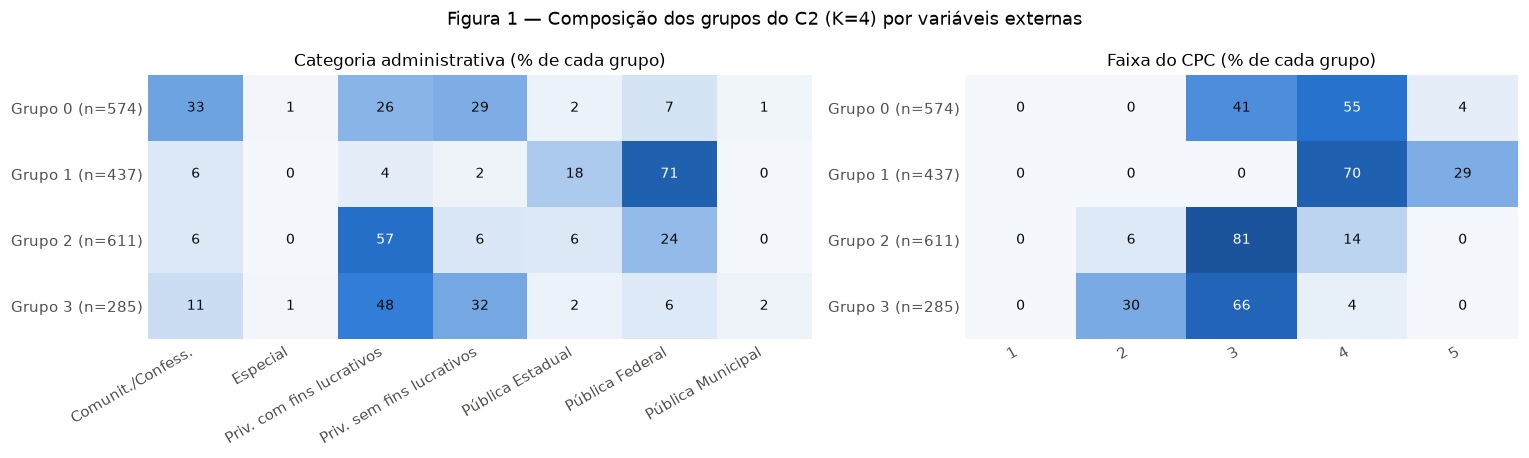

In [6]:
# Célula 6 — Figura 1: composição dos grupos

cmap_seq = LinearSegmentedColormap.from_list("azul", ["#f4f7fb", COR_1, "#123f7a"])

fig, eixos = plt.subplots(1, 2, figsize=(14, 4.2),
                          gridspec_kw={"width_ratios": [6, 5]})

for ax, nome in zip(eixos, ["Categoria administrativa", "Faixa do CPC"]):
    tabela = tabelas_externas[nome]
    imagem = ax.imshow(tabela.to_numpy(), cmap=cmap_seq, vmin=0, vmax=100, aspect="auto")

    for i in range(tabela.shape[0]):
        for j in range(tabela.shape[1]):
            valor = tabela.iat[i, j]
            ax.text(j, i, f"{valor:.0f}", ha="center", va="center", fontsize=9,
                    color="white" if valor > 50 else "#0b0b0b")

    rotulos = [str(c).replace("Privada ", "Priv. ").replace("Comunitária/Confessional", "Comunit./Confess.")
               for c in tabela.columns]
    ax.set_xticks(range(tabela.shape[1]), rotulos, rotation=30, ha="right")
    ax.set_yticks(range(tabela.shape[0]),
                  [f"Grupo {g} (n={tamanhos[g]})" for g in tabela.index])
    ax.set_title(f"{nome} (% de cada grupo)")
    ax.grid(visible=False)
    ax.tick_params(length=0)
    for lado in ax.spines.values():
        lado.set_visible(False)

fig.suptitle("Figura 1 — Composição dos grupos do C2 (K=4) por variáveis externas", fontsize=12)
plt.tight_layout()
salvar_figura(fig, "figura_1_validacao_externa.png")
plt.show()

### Leitura

Os quatro grupos podem receber nomes a partir dos centróides e da composição externa:

| Grupo | Perfil nos indicadores | Composição externa |
|---|---|---|
| 1 (437) | ENADE, IDD e corpo docente acima da média; condições de formação abaixo | 89% públicos; quase todos (99,8%) com CPC 4 ou 5 |
| 0 (574) | Condições de formação bem acima da média | 62% privados sem fins lucrativos ou comunitários; 59% com CPC 4 ou 5 |
| 2 (611) | ENADE, IDD e condições de formação abaixo da média | 57% privados com fins lucrativos; 81% com CPC 3 |
| 3 (285) | Corpo docente bem abaixo da média | 90% privados; 96% com CPC 2 ou 3 |

- **Os grupos não repetem a área:** a associação com a área de avaliação é fraca (0,12). Isso confirma que comparar cursos de áreas diferentes no mesmo grupo é razoável.
- **Os grupos acompanham o CPC e a categoria administrativa** sem que essas variáveis tenham sido usadas. É evidência de que os perfis têm significado institucional.
- **Cuidado:** o Grupo 1 é quase todo público. Um curso privado que caia nele, como a Engenharia Civil da PUC-Rio, terá pares majoritariamente públicos.

## 3. Regime de Trabalho e categoria administrativa

O artigo de Marcatti et al. excluiu o Regime de Trabalho porque, nas federais, quase todos os cursos têm nota 5. Na base completa ele varia, mas a diferença entre públicas e privadas pode afetar a comparação dos cursos da PUC-Rio, que é comunitária e confessional.

In [7]:
# Célula 7 — Regime de Trabalho: comparação com pares públicos e privados

print("Regime de Trabalho por tipo de instituição (base completa)")
display(
    base.groupby("Tipo")["Regime_Trabalho_2023"]
    .agg(Cursos="count", Média="mean", Mediana="median")
    .round(2)
)

linhas = []

for _, curso in base[mascara_puc].iterrows():

    area = base[
        base["Area_2023"].eq(curso["Area_2023"])
        & base["Código do Curso"].ne(curso["Código do Curso"])
    ]
    pares = area[area["Grupo"].eq(curso["Grupo"])]
    pares_privados = pares[pares["Tipo"].eq("Privada")]
    privadas_area = area[area["Tipo"].eq("Privada")]

    regime = curso["Regime_Trabalho_2023"]

    linhas.append({
        "Curso": curso["Código do Curso"],
        "Área": curso["Area_2023"],
        "Regime PUC-Rio": regime,
        "Pares": len(pares),
        "% públicos nos pares": 100 * pares["Tipo"].eq("Pública").mean(),
        "Dif. todos os pares": regime - pares["Regime_Trabalho_2023"].mean(),
        "Pares privados": len(pares_privados),
        "Dif. pares privados": regime - pares_privados["Regime_Trabalho_2023"].mean(),
        "Dif. privadas da área": regime - privadas_area["Regime_Trabalho_2023"].mean()
    })

regime_puc = pd.DataFrame(linhas).set_index("Curso")

print("\nPUC-Rio − média de cada referência (Regime de Trabalho)")
display(regime_puc.round(2))

print("Média das diferenças:")
print(regime_puc.filter(like="Dif.").mean().round(2).to_string())
print("Diferença negativa em todos os cursos e referências:",
      bool((regime_puc.filter(like="Dif.") < 0).all().all()))

Regime de Trabalho por tipo de instituição (base completa)


,Cursos,Média,Mediana
Tipo,,,
Privada,1249,3.71,4.05
Pública,658,4.90,5.00



PUC-Rio − média de cada referência (Regime de Trabalho)


,Área,Regime PUC-Rio,Pares,% públicos nos pares,Dif. todos os pares,Pares privados,Dif. pares privados,Dif. privadas da área
Curso,,,,,,,,
59962,21,0.00,54,1.85,-2.60,53,-2.61,-3.66
29445,5710,2.46,84,96.43,-2.50,3,-2.27,-1.32
29446,5806,2.88,73,10.96,-1.17,65,-1.12,-0.78
32655,5814,2.84,39,38.46,-1.47,24,-1.04,-0.80
23702,5902,2.33,61,91.80,-2.61,5,-2.39,-1.31
32975,6008,2.97,24,95.83,-1.98,1,-1.53,-1.17
44431,6208,1.90,110,10.00,-2.12,99,-2.06,-1.84
70523,6307,3.07,36,58.33,-1.38,15,-0.82,-0.56


Média das diferenças:
Dif. todos os pares     -1.98
Dif. pares privados     -1.73
Dif. privadas da área   -1.43
Diferença negativa em todos os cursos e referências: True


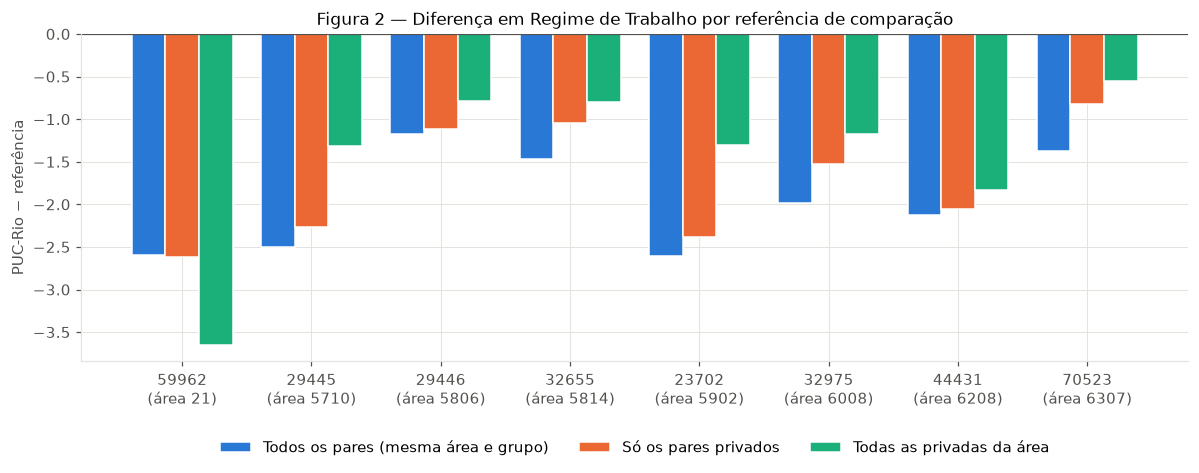

In [8]:
# Célula 8 — Figura 2: a diferença diminui, mas não some, ao comparar só com privadas

referencias = [
    ("Dif. todos os pares", "Todos os pares (mesma área e grupo)", COR_1),
    ("Dif. pares privados", "Só os pares privados", COR_2),
    ("Dif. privadas da área", "Todas as privadas da área", COR_3)
]

fig, ax = plt.subplots(figsize=(11, 4.5))

posicoes = np.arange(len(regime_puc))
largura = 0.26

for i, (coluna, rotulo, cor) in enumerate(referencias):
    ax.bar(posicoes + (i - 1) * largura, regime_puc[coluna], largura,
           color=cor, label=rotulo, edgecolor="white", linewidth=1)

ax.axhline(0, color=COR_TEXTO, linewidth=0.8)
ax.set_xticks(posicoes, [f"{c}\n(área {a})" for c, a in zip(regime_puc.index, regime_puc["Área"])])
ax.set_ylabel("PUC-Rio − referência")
ax.set_title("Figura 2 — Diferença em Regime de Trabalho por referência de comparação")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.2), ncols=3)

plt.tight_layout()
salvar_figura(fig, "figura_2_regime_publicas_privadas.png")
plt.show()

### Leitura

- **Públicas e privadas diferem muito:** Regime de Trabalho médio de 4,90 nas públicas e 3,71 nas privadas.
- **Nos pares da Engenharia Civil, 96% são públicos.** O mesmo ocorre nos cursos 23702 (92%) e 32975 (96%).
- **A diferença diminui contra privadas, mas não some.** Em média, vai de −1,98 (todos os pares) para −1,73 (pares privados) e −1,43 (todas as privadas da área). É negativa nos 8 cursos e nas três referências.
- **Os pares privados às vezes são poucos:** 3 na Civil e 1 no curso 32975. Nesses casos, a comparação com todas as privadas da área é mais confiável.

**Conclusão:** parte da diferença reflete o padrão das instituições privadas, mas os cursos da PUC-Rio têm Regime de Trabalho abaixo até das privadas da mesma área. O diagnóstico deve informar a composição pública e privada dos pares.

## 4. Outras famílias de algoritmos

A aula apresenta métodos de partição (k-means, k-medoids), hierárquicos, baseados em densidade (DBSCAN) e baseados em modelo (GMM). Todos foram aplicados aos mesmos oito indicadores padronizados, com K=4 quando o método exige K. A estabilidade compara, em 30 subamostras de 80% dos cursos, o agrupamento da subamostra com o da base completa.

In [9]:
# Célula 9 — Outras famílias de algoritmos (aula de Agrupamento)

def k_medoides(D, k, semente, n_init=10, max_iter=100):
    """K-medoids (PAM simplificado, por alternância) sobre uma matriz de distâncias."""
    gerador = np.random.default_rng(semente)
    melhor_custo, melhores_rotulos = np.inf, None
    n = len(D)

    for _ in range(n_init):
        # Inicialização no estilo k-means++
        medoides = [gerador.integers(n)]
        while len(medoides) < k:
            d_min = D[:, medoides].min(axis=1) ** 2
            medoides.append(gerador.choice(n, p=d_min / d_min.sum()))
        medoides = np.array(medoides)

        for _ in range(max_iter):
            rotulos = D[:, medoides].argmin(axis=1)
            novos = np.array([
                np.flatnonzero(rotulos == g)[
                    D[np.ix_(rotulos == g, rotulos == g)].sum(axis=1).argmin()
                ]
                for g in range(k)
            ])
            if np.array_equal(np.sort(novos), np.sort(medoides)):
                break
            medoides = novos

        custo = D[np.arange(n), medoides[rotulos]].sum()
        if custo < melhor_custo:
            melhor_custo, melhores_rotulos = custo, rotulos

    return melhores_rotulos


def agrupar(nome, dados, semente=SEMENTE):
    if nome == "K-means":
        return KMeans(n_clusters=K, random_state=semente, n_init=N_INIT).fit_predict(dados)
    if nome == "Hierárquico (Ward)":
        return AgglomerativeClustering(n_clusters=K, linkage="ward").fit_predict(dados)
    if nome == "Mistura gaussiana (GMM)":
        return GaussianMixture(n_components=K, covariance_type="full",
                               random_state=semente, n_init=5).fit(dados).predict(dados)
    if nome == "K-medoids":
        return k_medoides(pairwise_distances(dados), K, semente)
    raise ValueError(nome)


ALGORITMOS = ["K-means", "Hierárquico (Ward)", "Mistura gaussiana (GMM)", "K-medoids"]

inicio = time.time()
rotulos_alg = {}
linhas = []

for nome in ALGORITMOS:

    rotulos = agrupar(nome, X)
    rotulos_alg[nome] = rotulos

    # Estabilidade: ajuste em 80% dos cursos comparado ao ajuste completo
    estabilidade = []
    for semente in SEMENTES:
        gerador = np.random.default_rng(semente)
        idx = gerador.choice(len(X), size=int(FRACAO_AMOSTRA * len(X)), replace=False)
        estabilidade.append(
            adjusted_rand_score(rotulos[idx], agrupar(nome, X[idx], semente))
        )

    linhas.append({
        "Algoritmo": nome,
        "Silhueta": silhouette_score(X, rotulos),
        "Davies–Bouldin": davies_bouldin_score(X, rotulos),
        "Estabilidade (ARI médio)": np.mean(estabilidade),
        "Estabilidade (ARI mínimo)": np.min(estabilidade),
        "Concordância com K-means (ARI)": adjusted_rand_score(rotulos_alg["K-means"], rotulos),
        "Menor grupo": np.bincount(rotulos).min(),
        "Maior grupo": np.bincount(rotulos).max()
    })

comparacao_alg = pd.DataFrame(linhas).set_index("Algoritmo")

print(f"Tempo: {time.time() - inicio:.0f} s")
display(comparacao_alg.round(3))

Tempo: 36 s


,Silhueta,Davies–Bouldin,Estabilidade (ARI médio),Estabilidade (ARI mínimo),Concordância com K-means (ARI),Menor grupo,Maior grupo
Algoritmo,,,,,,,
K-means,0.239,1.372,0.973,0.923,1.000,285,611
Hierárquico (Ward),0.193,1.517,0.414,0.254,0.519,251,814
Mistura gaussiana (GMM),0.039,2.234,0.792,0.411,0.190,266,924
K-medoids,0.218,1.500,0.574,0.409,0.677,389,588


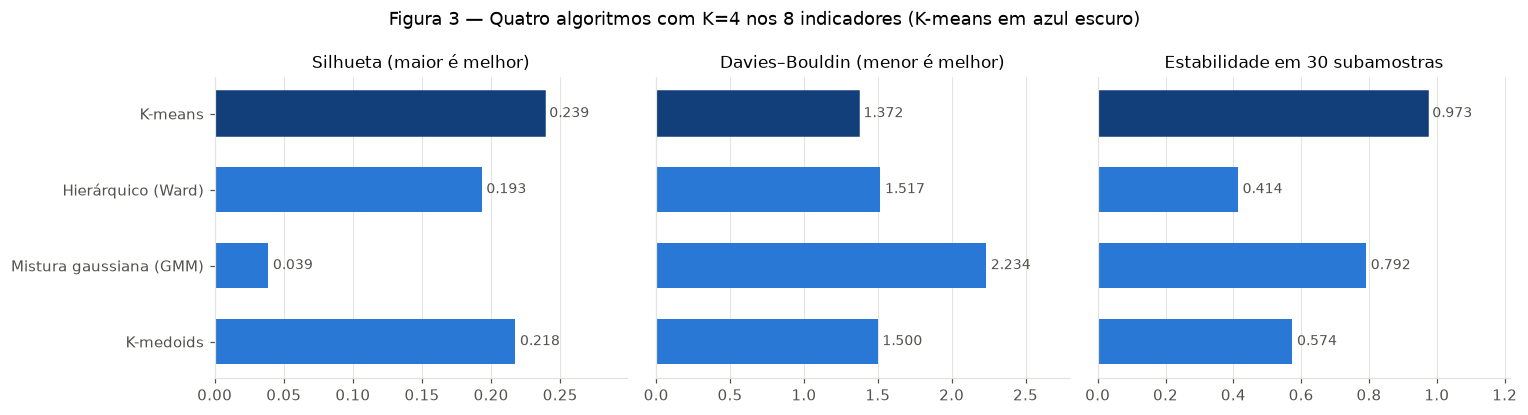

In [10]:
# Célula 10 — Figura 3: qualidade e estabilidade por algoritmo

fig, eixos = plt.subplots(1, 3, figsize=(14, 3.8))

metricas = [
    ("Silhueta", "Silhueta (maior é melhor)"),
    ("Davies–Bouldin", "Davies–Bouldin (menor é melhor)"),
    ("Estabilidade (ARI médio)", "Estabilidade em 30 subamostras")
]

for ax, (coluna, titulo) in zip(eixos, metricas):
    valores = comparacao_alg[coluna]
    barras = ax.barh(valores.index, valores, color=COR_1, height=0.6)
    barras[0].set_color("#123f7a")
    ax.bar_label(barras, fmt="%.3f", padding=3, fontsize=9, color=COR_TEXTO)
    ax.set_title(titulo)
    ax.invert_yaxis()
    ax.set_xlim(0, valores.max() * 1.25)
    ax.grid(axis="y", visible=False)

for ax in eixos[1:]:
    ax.set_yticks([])

fig.suptitle("Figura 3 — Quatro algoritmos com K=4 nos 8 indicadores (K-means em azul escuro)", fontsize=12)
plt.tight_layout()
salvar_figura(fig, "figura_3_comparacao_algoritmos.png")
plt.show()

In [11]:
# Célula 11 — DBSCAN (baseado em densidade) como diagnóstico

linhas = []

for eps in [0.8, 1.0, 1.2, 1.5, 2.0]:
    rotulos = DBSCAN(eps=eps, min_samples=2 * len(INDICADORES)).fit_predict(X)
    grupos = sorted(set(rotulos) - {-1})
    tamanhos_db = [int((rotulos == g).sum()) for g in grupos]
    linhas.append({
        "eps": eps,
        "Grupos encontrados": len(grupos),
        "% ruído": 100 * (rotulos == -1).mean(),
        "Tamanho dos grupos": tamanhos_db[:5]
    })

display(pd.DataFrame(linhas).set_index("eps").round(1))

,Grupos encontrados,% ruído,Tamanho dos grupos
eps,,,
0.8,2,88.7,"[59, 156]"
1.0,2,58.6,"[780, 10]"
1.2,1,30.2,[1331]
1.5,1,9.6,[1724]
2.0,1,1.2,[1885]


In [12]:
# Célula 12 — Mistura gaussiana: quão "de fronteira" é cada curso?

gmm = GaussianMixture(n_components=K, covariance_type="full",
                      random_state=SEMENTE, n_init=5).fit(X)
probabilidades = gmm.predict_proba(X)
prob_max = probabilidades.max(axis=1)

ordenadas = np.sort(probabilidades, axis=1)
base["GMM_prob_grupo"] = prob_max
base["GMM_prob_segundo"] = ordenadas[:, -2]

print("Cursos com probabilidade máxima abaixo de 0,8 (fronteira):",
      f"{100 * (prob_max < 0.8).mean():.1f}% da base")

print("\nCursos da PUC-Rio")
display(
    base.loc[mascara_puc, ["Código do Curso", "Area_2023", "GMM_prob_grupo", "GMM_prob_segundo"]]
    .sort_values("Código do Curso")
    .round(3)
)

Cursos com probabilidade máxima abaixo de 0,8 (fronteira): 10.5% da base

Cursos da PUC-Rio


,Código do Curso,Area_2023,GMM_prob_grupo,GMM_prob_segundo
1139,23702,5902,0.999,0.001
435,29445,5710,0.999,0.001
801,29446,5806,0.996,0.004
985,32655,5814,0.998,0.002
1388,32975,6008,0.618,0.379
1550,44431,6208,0.998,0.002
133,59962,21,0.880,0.120
1784,70523,6307,0.999,0.001


In [13]:
# Célula 13 — Os pares dos cursos da PUC-Rio mudam com o algoritmo?

linhas = []

for i in np.flatnonzero(mascara_puc):

    area = base["Area_2023"].eq(base.loc[i, "Area_2023"]).to_numpy().copy()
    area[i] = False

    def pares(rotulos):
        return set(np.flatnonzero(area & (rotulos == rotulos[i])))

    referencia = pares(rotulos_alg["K-means"])
    linha = {"Curso": base.loc[i, "Código do Curso"], "Pares K-means": len(referencia)}

    for nome in ALGORITMOS[1:]:
        outro = pares(rotulos_alg[nome])
        uniao = referencia | outro
        linha[f"Jaccard {nome}"] = len(referencia & outro) / len(uniao) if uniao else 1.0

    linhas.append(linha)

pares_alg = pd.DataFrame(linhas).set_index("Curso").sort_index()

print("Jaccard entre os pares do K-means e os de cada algoritmo (1 = mesmos pares)")
display(pares_alg.round(2))

Jaccard entre os pares do K-means e os de cada algoritmo (1 = mesmos pares)


,Pares K-means,Jaccard Hierárquico (Ward),Jaccard Mistura gaussiana (GMM),Jaccard K-medoids
Curso,,,,
23702,61,0.06,0.04,0.94
29445,84,0.02,0.00,0.90
29446,73,0.61,0.28,0.04
32655,39,0.73,0.21,0.64
32975,24,0.00,0.00,0.88
44431,110,0.72,0.41,0.81
59962,54,0.68,0.01,0.09
70523,36,0.60,0.22,0.76


### Leitura

- **O k-means é o melhor nos três critérios:** silhueta 0,239, Davies–Bouldin 1,37 e estabilidade 0,97. Ward fica com 0,193 e estabilidade 0,41; k-medoids, com 0,218 e 0,57; GMM, com 0,039 e 0,79.
- **O DBSCAN encontra um único bloco.** Com raio pequeno, quase tudo vira ruído (até 89%); com raio maior, um só grupo reúne de 70% a 99% dos cursos. Isso confirma o que a aula indica sobre o DBSCAN com densidades variadas e mais dimensões, e reforça que os cursos formam uma distribuição contínua.
- **GMM:** apenas 10,5% dos cursos ficam abaixo de 80% de probabilidade de pertencer ao seu grupo. Entre os cursos da PUC-Rio, o 32975 é o mais dividido (62% e 38%). Essa medida se refere aos grupos do GMM, que concordam pouco com os do k-means (ARI 0,19).
- **Os pares dependem da família do algoritmo.** O k-medoids, também de partição por centro, mantém a maior parte dos pares do k-means em 6 dos 8 cursos (Jaccard de 0,64 a 0,94). Ward e GMM produzem pares bem diferentes. Por isso, o achado principal foi confirmado também sem agrupamento, por vizinhos mais próximos.

**Conclusão:** a escolha do k-means não foi por conveniência. Ele supera as outras famílias em qualidade e estabilidade nesses dados.

## 5. Separar públicas e privadas melhora a silhueta?

In [14]:
# Célula 14 — Separar públicas e privadas melhora a silhueta?

linhas = []

for nome, mascara in [
    ("Base completa", np.ones(len(base), dtype=bool)),
    ("Só privadas", base["Tipo"].eq("Privada").to_numpy()),
    ("Só públicas", base["Tipo"].eq("Pública").to_numpy())
]:
    Xs = StandardScaler().fit_transform(base.loc[mascara, INDICADORES])
    linha = {"Subconjunto": nome, "Cursos": int(mascara.sum())}
    for k in range(2, 7):
        r = KMeans(n_clusters=k, random_state=SEMENTE, n_init=N_INIT).fit_predict(Xs)
        linha[f"K={k}"] = silhouette_score(Xs, r)
    linhas.append(linha)

silhueta_sub = pd.DataFrame(linhas).set_index("Subconjunto")

print("Silhueta do K-means por subconjunto e K (padronização refeita em cada subconjunto)")
display(silhueta_sub.round(3))

Silhueta do K-means por subconjunto e K (padronização refeita em cada subconjunto)


,Cursos,K=2,K=3,K=4,K=5,K=6
Subconjunto,,,,,,
Base completa,1907,0.218,0.228,0.239,0.231,0.207
Só privadas,1249,0.248,0.241,0.188,0.189,0.180
Só públicas,658,0.220,0.204,0.214,0.218,0.192


### Leitura

Não de forma relevante. A maior silhueta é 0,248 (só privadas, K=2), contra 0,239 na base completa com K=4. Com K=4, as privadas caem para 0,188 e as públicas ficam em 0,214. Separar por categoria não revela grupos mais nítidos: a estrutura fraca é uma característica dos dados, não um efeito de misturar públicas e privadas.

## 6. Síntese para o trabalho

1. **Validação externa:** os grupos se associam à faixa do CPC e à categoria administrativa, sem dependerem da área. Isso dá significado aos perfis e permite nomeá-los.
2. **Regime de Trabalho:** o achado se mantém, mas com magnitude menor quando a comparação é feita com instituições privadas. O texto deve apresentar as duas comparações.
3. **Algoritmos:** o k-means é o mais adequado entre as famílias apresentadas na aula. O DBSCAN confirma a ausência de grupos densos e separados.
4. **Silhueta:** nenhuma alternativa testada (outros algoritmos ou subconjuntos) a eleva de forma relevante. A silhueta baixa é uma propriedade dos dados.

**Limitações:** a validação externa mostra associação, não causa. Os pares privados são poucos em algumas áreas. A estabilidade foi medida por subamostragem sem reposição, e os resultados descrevem o ciclo de 2023.

## 7. Exportação

In [15]:
# Célula 15 — Exportar resultados

saidas = {
    "validacao_externa_V_cramer.csv": pd.Series(associacoes, name="V_de_Cramer").reset_index(),
    "regime_puc_por_referencia.csv": regime_puc.reset_index(),
    "comparacao_algoritmos.csv": comparacao_alg.reset_index(),
    "pares_puc_por_algoritmo.csv": pares_alg.reset_index(),
    "silhueta_por_subconjunto.csv": silhueta_sub.reset_index()
}

for nome, tabela in saidas.items():
    tabela.to_csv(pasta_saida / nome, index=False, sep=";", decimal=",", encoding="utf-8-sig")

for nome, tabela in tabelas_externas.items():
    tabela.round(2).to_csv(
        pasta_saida / f"composicao_grupos_{nome.lower().replace(' ', '_')}.csv",
        sep=";", decimal=",", encoding="utf-8-sig"
    )

print("ARQUIVOS EXPORTADOS")
print("-" * 45)
for caminho in sorted(pasta_saida.rglob("*.*")):
    print(caminho)

ARQUIVOS EXPORTADOS
---------------------------------------------
resultados_notebook_08\comparacao_algoritmos.csv
resultados_notebook_08\composicao_grupos_categoria_administrativa.csv
resultados_notebook_08\composicao_grupos_faixa_do_cpc.csv
resultados_notebook_08\composicao_grupos_organização_acadêmica.csv
resultados_notebook_08\composicao_grupos_área_de_avaliação.csv
resultados_notebook_08\figuras\figura_1_validacao_externa.png
resultados_notebook_08\figuras\figura_2_regime_publicas_privadas.png
resultados_notebook_08\figuras\figura_3_comparacao_algoritmos.png
resultados_notebook_08\pares_puc_por_algoritmo.csv
resultados_notebook_08\regime_puc_por_referencia.csv
resultados_notebook_08\silhueta_por_subconjunto.csv
resultados_notebook_08\validacao_externa_V_cramer.csv
